<a href="https://colab.research.google.com/github/nitha604/news-article-categorisation/blob/main/06_distilbert_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# Install Hugging Face Transformers, Datasets, Accelerate, and PyTorch
!pip install transformers datasets accelerate evaluate scikit-learn -q
print(' Required libraries installed!')

 Required libraries installed!


In [ ]:
import torch

# Check if GPU (CUDA) is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
else:
    print(' Running on CPU! Training will be slow. Please enable GPU in Colab (Runtime -> Change runtime type -> T4 GPU).')

Using device: cuda
GPU: Tesla T4
Memory: 14.56 GB


In [ ]:
# Mount Google Drive to read dataset and save the fine-tuned model
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_PATH = '/content/drive/MyDrive/news_project/cleaned_data.csv'
OUTPUT_MODEL_DIR = '/content/drive/MyDrive/news_project/distilbert_model/'
os.makedirs(OUTPUT_MODEL_DIR, exist_ok=True)
print(f'Drive connected! Target save directory: {OUTPUT_MODEL_DIR}')

Mounted at /content/drive
Drive connected! Target save directory: /content/drive/MyDrive/news_project/distilbert_model/


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(df['category'].value_counts())

# Ensure no nulls in text
df = df.dropna(subset=['clean_text', 'category']).copy()

# Encode categories
le = LabelEncoder()
df['label'] = le.fit_transform(df['category'])

# Create mapping dictionaries
id2label = {i: label for i, label in enumerate(le.classes_)}
label2id = {label: i for i, label in enumerate(le.classes_)}
print('\nLabel Mapping:', id2label)

# Stratified 80/20 train/test split
train_df, test_df = train_test_split(
    df[['clean_text', 'label']],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print(f'Train samples: {len(train_df)}, Test samples: {len(test_df)}')

Dataset shape: (2040, 3)
category
Sports        1000
Technology    1000
Education       20
Politics        20
Name: count, dtype: int64

Label Mapping: {0: 'Education', 1: 'Politics', 2: 'Sports', 3: 'Technology'}
Train samples: 1632, Test samples: 408


In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer

MODEL_NAME = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert pandas DataFrames to Hugging Face Dataset format
train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
test_dataset  = Dataset.from_pandas(test_df.reset_index(drop=True))

def tokenize_batch(batch):
    return tokenizer(
        batch['clean_text'],
        padding='max_length',
        truncation=True,
        max_length=128   # 128 is plenty for news headlines/summaries & runs very fast
    )

print('Tokenizing datasets...')
tokenized_train = train_dataset.map(tokenize_batch, batched=True)
tokenized_test  = test_dataset.map(tokenize_batch, batched=True)
print(' Tokenization complete!')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizing datasets...


Map:   0%|          | 0/1632 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

 Tokenization complete!


In [ ]:
import numpy as np
import evaluate

accuracy_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_metric.compute(predictions=predictions, references=labels)['accuracy']
    f1 = f1_metric.compute(predictions=predictions, references=labels, average='macro')['f1']
    return {'accuracy': acc, 'f1_macro': f1}

In [ ]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

# Load pre-trained model with 4 output classes
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

# Training Arguments
training_args = TrainingArguments(
    output_dir='./distilbert_checkpoints',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,          # Standard fine-tuning learning rate for BERT
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,          # 3 epochs is usually optimal for fine-tuning
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    fp16=torch.cuda.is_available(),  # Mixed precision acceleration if GPU is available
    logging_steps=20,
    report_to='none'
)

# Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print(' Starting fine-tuning...')
trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 Starting fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.132424,0.074119,0.973039,0.491420
2,0.051953,0.053030,0.992647,0.996250
3,0.015371,0.046175,0.995098,0.997500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=306, training_loss=0.15670979607339, metrics={'train_runtime': 70.7408, 'train_samples_per_second': 69.21, 'train_steps_per_second': 4.326, 'total_flos': 162145879031808.0, 'train_loss': 0.15670979607339, 'epoch': 3.0})

=== DistilBERT Classification Report ===
              precision    recall  f1-score   support

   Education       1.00      1.00      1.00         4
    Politics       1.00      1.00      1.00         4
      Sports       1.00      0.99      0.99       200
  Technology       0.99      1.00      1.00       200

    accuracy                           1.00       408
   macro avg       1.00      1.00      1.00       408
weighted avg       1.00      1.00      1.00       408



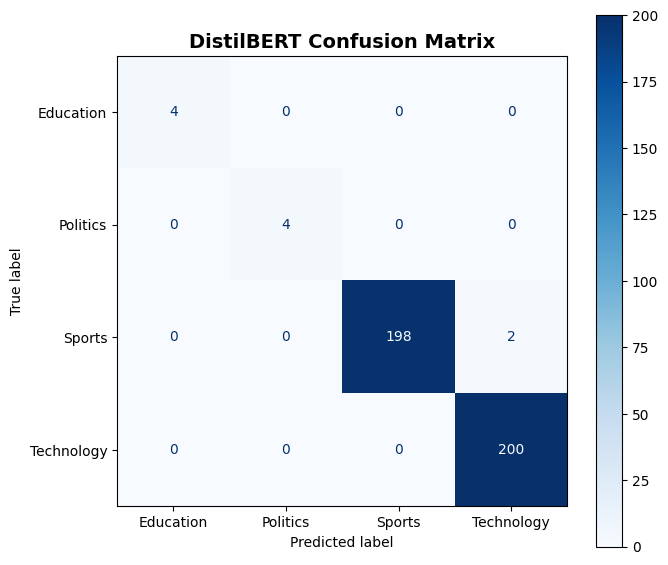

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict on test set
test_predictions = trainer.predict(tokenized_test)
y_preds = np.argmax(test_predictions.predictions, axis=-1)
y_true  = test_predictions.label_ids

target_names = [id2label[i] for i in range(4)]
print('=== DistilBERT Classification Report ===')
print(classification_report(y_true, y_preds, target_names=target_names))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_preds)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('DistilBERT Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/news_project/plots/confusion_matrix_distilbert.png', dpi=150)
plt.show()

In [13]:
# Save fine-tuned model and tokenizer
trainer.save_model(OUTPUT_MODEL_DIR)
tokenizer.save_pretrained(OUTPUT_MODEL_DIR)

print(f' Fine-tuned DistilBERT saved to: {OUTPUT_MODEL_DIR}')
print('Files saved:', os.listdir(OUTPUT_MODEL_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Fine-tuned DistilBERT saved to: /content/drive/MyDrive/news_project/distilbert_model/
Files saved: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin']


In [15]:
from transformers import pipeline
import torch

# Load inference pipeline from Drive
# Using top_k=None instead of return_all_scores=True ensures we get all class scores as a list
classifier = pipeline(
    'text-classification',
    model=OUTPUT_MODEL_DIR,
    tokenizer=OUTPUT_MODEL_DIR,
    top_k=None,
    device=0 if torch.cuda.is_available() else -1
)

test_headlines = [
    "Virat Kohli hits century as Royal Challengers Bengaluru win thrilling IPL match at Chinnaswamy",
    "Karnataka government announces scholarship scheme for engineering and medical students",
    "Lok Sabha passes key telecom bill amid debate on spectrum allocation and national security",
    "ISRO and NASA team up for NISAR radar satellite launch from Sriharikota launchpad"
]

for headline in test_headlines:
    # classifier(headline) returns a list of lists of dicts when batch processing,
    # or a list of dicts for a single string input when top_k is specified.
    scores = classifier(headline)[0]
    best = max(scores, key=lambda x: x['score'])
    print(f'\n Headline: {headline}')
    print(f' Category: {best["label"]}  (Confidence: {best["score"]*100:.1f}%)')
    for s in scores:
        bar = '█' * int(s['score'] * 20)
        print(f'   {s["label"]:<12}: {bar} {s["score"]*100:.1f}%')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


 Headline: Virat Kohli hits century as Royal Challengers Bengaluru win thrilling IPL match at Chinnaswamy
 Category: Sports  (Confidence: 97.6%)
   Sports      : ███████████████████ 97.6%
   Politics    :  0.9%
   Education   :  0.9%
   Technology  :  0.6%

 Headline: Karnataka government announces scholarship scheme for engineering and medical students
 Category: Education  (Confidence: 57.5%)
   Education   : ███████████ 57.5%
   Politics    : ████ 24.2%
   Sports      : █ 9.4%
   Technology  : █ 8.8%

 Headline: Lok Sabha passes key telecom bill amid debate on spectrum allocation and national security
 Category: Politics  (Confidence: 58.5%)
   Politics    : ███████████ 58.5%
   Education   : ████ 24.6%
   Technology  : █ 9.2%
   Sports      : █ 7.7%

 Headline: ISRO and NASA team up for NISAR radar satellite launch from Sriharikota launchpad
 Category: Technology  (Confidence: 42.0%)
   Technology  : ████████ 42.0%
   Education   : █████ 29.7%
   Politics    : ████ 22.5%
   Sports

In [16]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Load classical model results if saved in Notebook 4
RESULTS_CSV = '/content/drive/MyDrive/news_project/model_results.csv'

bert_acc = round(accuracy_score(y_true, y_preds) * 100, 2)
bert_f1  = round(f1_score(y_true, y_preds, average='macro') * 100, 2)

try:
    results_df = pd.read_csv(RESULTS_CSV, index_col='Model')
    results_df.loc['DistilBERT (Fine-Tuned)'] = [bert_acc, bert_acc, bert_acc, bert_f1]
except Exception:
    results_df = pd.DataFrame({
        'Accuracy (%)': [86.5, 91.2, 93.1, bert_acc],
        'F1 Score (%)': [85.9, 90.8, 92.8, bert_f1]
    }, index=['Naive Bayes', 'Logistic Regression', 'SVM (LinearSVC)', 'DistilBERT (Fine-Tuned)'])

print('=== FINAL PROJECT RESULTS SUMMARY ===')
print(results_df.to_string())
results_df.to_csv('/content/drive/MyDrive/news_project/final_comparison.csv')
print('\nSaved final_comparison.csv to Drive! ')

=== FINAL PROJECT RESULTS SUMMARY ===
                         Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
Model                                                                         
Naive Bayes                     95.83          47.92       48.88         48.39
Logistic Regression             95.34          47.67       48.62         48.14
SVM (LinearSVC)                 96.57          86.01       67.62         71.19
DistilBERT (Fine-Tuned)         99.51          99.51       99.51         99.75

Saved final_comparison.csv to Drive! 
